# MeterTrace — Notebook 05: Deep Learning Models

**Project:** MeterTrace: Electricity Theft Detection and Consumption Anomaly Analysis
**Phase:** 5 of 8

## Purpose
Train the two deep learning models from our proposal on the **148-week consumption sequences** built in
Notebook 02, and compare them with the Notebook 04 baselines on **validation** customers.

| Model | Branch | Trained on | Output |
|---|---|---|---|
| **LSTM classifier** | Supervised | All training customers, with theft labels | Theft probability |
| **Dense autoencoder** | Unsupervised | **Normal** training customers only, **no** labels as targets | Reconstruction error = anomaly score |

The question for each model:
- **LSTM:** does learning directly from the weekly sequence beat hand-made features (LR / Random Forest)?
- **Autoencoder:** does a learned picture of "normal usage" flag theft better than Isolation Forest?

## Rules followed in this notebook
- We load the **existing** `weekly_train.npz` and `weekly_validation.npz` from Notebook 02: same customers,
  same order, same labels. Nothing is re-split, re-imputed or re-scaled.
- **The test file is not loaded.** Test customers are scored once, in Notebook 06.
- The autoencoder **never** uses theft labels as targets. Labels are used only to pick the normal customers
  it learns from, and later to *evaluate* its scores.
- No decision thresholds are chosen here (Notebook 06).

## Outputs
- `models/lstm_classifier.keras`, `models/dense_autoencoder.keras` (git-ignored)
- `outputs/results/05_validation_scores.csv`, `05_validation_metrics.csv`, `05_lstm_history.csv`,
  `05_autoencoder_history.csv` (committed)
- `outputs/figures/05_training_curves.png`, `05_reconstruction_examples.png`, `05_validation_comparison.png`

## 0. Setup: libraries, hardware and random seeds
*Note:* when TensorFlow is imported on a computer **without a GPU**, it prints a few lines such as
"oneDNN custom operations are on" and "Could not find cuda drivers". They come from TensorFlow's start-up,
before any setting can hide them. They are **information messages, not errors**, and training simply runs
on the CPU.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow's low-level C++ log messages (Python errors still show)

from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.utils.class_weight import compute_class_weight

I0000 00:00:1793257527.140954    2096 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793257527.141822    2096 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793257528.378168    2096 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793257528.378563    2096 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# ---- Reproducibility: same seed for Python, NumPy and TensorFlow, and deterministic operations ----
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))
print("CPU cores:", os.cpu_count())

TensorFlow: 2.21.0 | Keras: 3.15.1
GPUs available: []
CPU cores: 4


In [3]:
# ---- Paths (work from the notebooks/ folder or from the project root) ----
if Path.cwd().name == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
for folder in [MODEL_DIR, FIGURE_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- Parameters saved by Notebook 02 (never recomputed) ----
preprocessing_params = json.loads((PROCESSED_DIR / "preprocessing_params.json").read_text())
N_WEEKS = preprocessing_params["n_weeks"]
LOG_TRAIN_MEAN = preprocessing_params["log_train_mean"]
LOG_TRAIN_STD = preprocessing_params["log_train_std"]
WEEK_START_DATES = pd.date_range(preprocessing_params["first_date"], periods=N_WEEKS, freq="7D")

# ---- Training settings (kept small and fixed; no tuning) ----
MAX_EPOCHS = 15
BATCH_SIZE = 256
EARLY_STOPPING_PATIENCE = 3
LEARNING_RATE = 0.001
LSTM_UNITS = 32
DROPOUT_RATE = 0.2
AUTOENCODER_HIDDEN = 64
AUTOENCODER_BOTTLENECK = 16

DEEP_COLOR = "#2a78d6"       # deep learning models
CLASSICAL_COLOR = "#b4b3ad"  # classical baselines
NORMAL_COLOR = "#2a78d6"
THEFT_COLOR = "#eb6834"
NEUTRAL_COLOR = "#52514e"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Weeks per sequence:", N_WEEKS, "| scaling from Notebook 02: mean", LOG_TRAIN_MEAN, "std", LOG_TRAIN_STD)

Weeks per sequence: 148 | scaling from Notebook 02: mean 1.601755 std 1.103571


## 1. Load the weekly sequences (train and validation only)
Each `.npz` file from Notebook 02 contains:
- `values`: weekly consumption after `log1p` and scaling with the **training** mean and standard deviation,
- `observed`: the share of days in each week that had a real reading (0 = the week was imputed),
- `labels` and `customer_ids`.

In [4]:
train_file = np.load(PROCESSED_DIR / "weekly_train.npz")
validation_file = np.load(PROCESSED_DIR / "weekly_validation.npz")

X_train = train_file["values"]
observed_train = train_file["observed"]
y_train = train_file["labels"].astype(int)
train_ids = train_file["customer_ids"]

X_validation = validation_file["values"]
observed_validation = validation_file["observed"]
y_validation = validation_file["labels"].astype(int)
validation_ids = validation_file["customer_ids"]

print("X_train:", X_train.shape, "| theft:", int(y_train.sum()))
print("X_validation:", X_validation.shape, "| theft:", int(y_validation.sum()))
print("Sequence length matches preprocessing_params:", X_train.shape[1] == N_WEEKS)
print("Any missing values:", bool(np.isnan(X_train).any() or np.isnan(X_validation).any()))

X_train: (29657, 148) | theft: 2530
X_validation: (6354, 148) | theft: 540
Sequence length matches preprocessing_params: True
Any missing values: False


### Same customers and order as Notebook 04
The validation scores of all models must line up row by row, so we check that the validation order equals the
order used for the Notebook 04 scores.

In [5]:
notebook_04_scores = pd.read_csv(RESULTS_DIR / "04_validation_scores.csv", index_col="CONS_NO")

print("Validation order identical to Notebook 04:", bool((notebook_04_scores.index.to_numpy() == validation_ids).all()))
print("Validation labels identical to Notebook 04:", bool((notebook_04_scores["FLAG"].to_numpy() == y_validation).all()))
print("No customer in both train and validation:", len(set(train_ids) & set(validation_ids)) == 0)

Validation order identical to Notebook 04: True
Validation labels identical to Notebook 04: True
No customer in both train and validation: True


### How much of the input was imputed?
Notebook 02 filled weeks without any reading from the customer's own neighbouring weeks. The `observed`
arrays tell us how much of what the networks see is real. The models below receive only the consumption
values; the masks are used here to **document** the imputation.

In [6]:
imputation_rows = []
for split_name, observed_array, labels_array in [("train", observed_train, y_train), ("validation", observed_validation, y_validation)]:
    for class_name, class_value in [("normal", 0), ("theft", 1)]:
        class_observed = observed_array[labels_array == class_value]
        imputation_rows.append({
            "split": split_name,
            "class": class_name,
            "customers": len(class_observed),
            "weeks fully imputed (%)": (class_observed == 0).mean() * 100,
            "weeks partly observed (%)": ((class_observed > 0) & (class_observed < 1)).mean() * 100,
            "weeks fully observed (%)": (class_observed == 1).mean() * 100,
        })
imputation_summary = pd.DataFrame(imputation_rows).round(2)
imputation_summary

,split,class,customers,weeks fully imputed (%),weeks partly observed (%),weeks fully observed (%)
0,train,normal,27127,23.99,4.66,71.35
1,train,theft,2530,30.31,3.93,65.76
2,validation,normal,5814,23.86,4.68,71.46
3,validation,theft,540,30.23,3.87,65.90


**What we see.**
- **Fully imputed weeks:** about 24% of weeks for normal customers and about 30% for theft customers
  (train: 23.99% vs 30.31%; validation: 23.86% vs 30.23%).
- **Fully observed weeks:** 71.35% vs 65.76% in train.
- **Why the networks can tell:** the networks only receive consumption values, but the imputed stretches
  are visible in them as flat or straight-line segments (Notebook 02). A sequence model can therefore
  partly "see" that a meter started reporting late. That fact is linked to the label, as the
  `missing_ratio` feature showed, and we keep it in mind when interpreting results.

## 2. Model 1 — LSTM classifier (supervised)
An **LSTM** (Long Short-Term Memory) network reads the sequence **one week at a time** and keeps an internal
memory, so it can pick up patterns that unfold over time, such as a drop after a stable period.

Architecture (small on purpose):

| Layer | Output shape | Role |
|---|---|---|
| `Input` | (148, 1) | 148 weeks, 1 value per week |
| `LSTM(32)` | (32,) | reads the sequence and summarises it in 32 numbers |
| `Dropout(0.2)` | (32,) | randomly switches off 20% of those numbers during training, to reduce overfitting |
| `Dense(1, sigmoid)` | (1,) | theft probability between 0 and 1 |

Training choices:
- **Loss:** binary cross-entropy (the standard loss for yes/no classification). **Optimiser:** Adam
  (learning rate 0.001).
- **Class imbalance:** class weights computed from the **training** labels with scikit-learn's
  `"balanced"` rule, so each theft customer counts about 11 times as much as a normal one.
- **Early stopping:** after each epoch Keras measures the loss on validation customers (`val_loss`). If it has
  not improved for 3 epochs, training stops and the weights from the **best** epoch are restored. At most
  15 epochs.
- `validation_data=(X_validation, y_validation)` is passed explicitly. We never use `validation_split`,
  which would take the last rows of the training array without shuffling.

In [7]:
X_train_sequence = X_train[:, :, np.newaxis]          # (customers, 148 weeks, 1 feature)
X_validation_sequence = X_validation[:, :, np.newaxis]

class_weight_values = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train)
lstm_class_weight = {0: float(class_weight_values[0]), 1: float(class_weight_values[1])}
print("Class weights (from training labels):", {key: round(value, 3) for key, value in lstm_class_weight.items()})

lstm_model = keras.Sequential([
    keras.Input(shape=(N_WEEKS, 1)),
    keras.layers.LSTM(LSTM_UNITS),
    keras.layers.Dropout(DROPOUT_RATE),
    keras.layers.Dense(1, activation="sigmoid"),
], name="lstm_classifier")

lstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[keras.metrics.AUC(name="roc_auc"), keras.metrics.AUC(curve="PR", name="pr_auc")],
)
lstm_model.summary()

Class weights (from training labels): {0: 0.547, 1: 5.861}


Model: "lstm_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
lstm_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True)

start_time = time.perf_counter()
lstm_history = lstm_model.fit(
    X_train_sequence, y_train,
    validation_data=(X_validation_sequence, y_validation),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=lstm_class_weight,
    callbacks=[lstm_early_stopping],
    verbose=2,
)
lstm_training_seconds = time.perf_counter() - start_time

lstm_epochs_completed = len(lstm_history.history["loss"])
lstm_best_epoch = int(np.argmin(lstm_history.history["val_loss"])) + 1
print(f"\nTraining time: {lstm_training_seconds:.1f} s | epochs completed: {lstm_epochs_completed} "
      f"| best epoch (lowest val_loss, weights restored): {lstm_best_epoch}")

Epoch 1/15


116/116 - 8s - 73ms/step - loss: 0.6653 - pr_auc: 0.1598 - roc_auc: 0.6231 - val_loss: 0.6808 - val_pr_auc: 0.1904 - val_roc_auc: 0.6682


Epoch 2/15


116/116 - 6s - 55ms/step - loss: 0.6421 - pr_auc: 0.1965 - roc_auc: 0.6701 - val_loss: 0.6695 - val_pr_auc: 0.1944 - val_roc_auc: 0.6738


Epoch 3/15


...

Epoch 8/15


116/116 - 6s - 54ms/step - loss: 0.6304 - pr_auc: 0.2098 - roc_auc: 0.6965 - val_loss: 0.6817 - val_pr_auc: 0.2069 - val_roc_auc: 0.7068


Epoch 9/15


116/116 - 6s - 55ms/step - loss: 0.6349 - pr_auc: 0.2043 - roc_auc: 0.6875 - val_loss: 0.6516 - val_pr_auc: 0.2031 - val_roc_auc: 0.6890



Training time: 59.4 s | epochs completed: 9 | best epoch (lowest val_loss, weights restored): 6


In [9]:
lstm_validation_probability = lstm_model.predict(X_validation_sequence, batch_size=1024, verbose=0).ravel()

lstm_validation_auc = roc_auc_score(y_validation, lstm_validation_probability)
lstm_validation_pr_auc = average_precision_score(y_validation, lstm_validation_probability)
print(f"LSTM validation ROC-AUC = {lstm_validation_auc:.4f}, PR-AUC = {lstm_validation_pr_auc:.4f}")

LSTM validation ROC-AUC = 0.6925, PR-AUC = 0.2043


**What we see.**
- **Size and training:** the LSTM has only 4,385 trainable parameters. Training stopped after **9 epochs**
  because the validation loss had not improved for 3 epochs since its best value at **epoch 6**, whose
  weights were restored.
- **Validation result:** ROC-AUC **0.6925** and PR-AUC **0.2043**.
  - Better than random and slightly better than "average consumption alone" (0.6671 / 0.1897).
  - **Below** both feature-based models from Notebook 04 (Logistic Regression 0.7216, Random Forest 0.7628).
- **Noisy validation loss:** from epoch to epoch it moves up and down (see the curves below), and the
  validation ROC-AUC printed per epoch ranges from about 0.67 to 0.71. Small changes in training
  therefore change the result, which is typical for a small network on a noisy, imbalanced problem.

We report this result as it is. In this configuration, learning directly from the weekly sequence does
**not** beat the hand-made features.

## 3. Model 2 — Dense autoencoder (unsupervised)
An **autoencoder** learns to copy its input through a narrow **bottleneck**:

`148 weeks → Dense(64) → Dense(16) bottleneck → Dense(64) → 148 weeks`

- The **encoder** (148 → 64 → 16) has to squeeze a customer's 148 weekly values into just 16 numbers.
- The **decoder** (16 → 64 → 148) rebuilds the 148 weeks from those 16 numbers.
- Because it is trained **only on normal customers**, it learns to rebuild *normal-looking* usage well.
  Unusual usage is rebuilt badly.
- **Anomaly score** = the customer's **reconstruction error**: the mean squared difference between the real
  and rebuilt weeks. **A high score means "unusual", not "theft proven".**

Training choices:
- Input and target are the **same** sequence (`fit(X, X)`). No label is ever a target.
- Loss: mean squared error. Optimiser: Adam (learning rate 0.001). Hidden layers use ReLU. The output
  layer is linear, because scaled values can be negative.
- Early stopping on the reconstruction loss of **normal validation customers only** (patience 3, best
  weights restored, at most 15 epochs).

In [10]:
X_train_normal = X_train[y_train == 0]
X_validation_normal = X_validation[y_validation == 0]
print("Normal training customers (fit):", X_train_normal.shape[0])
print("Normal validation customers (early stopping only):", X_validation_normal.shape[0])

autoencoder = keras.Sequential([
    keras.Input(shape=(N_WEEKS,)),
    keras.layers.Dense(AUTOENCODER_HIDDEN, activation="relu", name="encoder_hidden"),
    keras.layers.Dense(AUTOENCODER_BOTTLENECK, activation="relu", name="bottleneck"),
    keras.layers.Dense(AUTOENCODER_HIDDEN, activation="relu", name="decoder_hidden"),
    keras.layers.Dense(N_WEEKS, activation="linear", name="reconstruction"),
], name="dense_autoencoder")

autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss="mse")
autoencoder.summary()

Normal training customers (fit): 27127
Normal validation customers (early stopping only): 5814


Model: "dense_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_hidden (Dense)          │ (None, 64)             │         9,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 148)            │         9,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,284 (83.14 KB)

 Trainable params: 21,284 (83.14 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
autoencoder_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True)

start_time = time.perf_counter()
autoencoder_history = autoencoder.fit(
    X_train_normal, X_train_normal,                         # input = target: no labels involved
    validation_data=(X_validation_normal, X_validation_normal),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[autoencoder_early_stopping],
    verbose=2,
)
autoencoder_training_seconds = time.perf_counter() - start_time

autoencoder_epochs_completed = len(autoencoder_history.history["loss"])
autoencoder_best_epoch = int(np.argmin(autoencoder_history.history["val_loss"])) + 1
print(f"\nTraining time: {autoencoder_training_seconds:.1f} s | epochs completed: {autoencoder_epochs_completed} "
      f"| best epoch (lowest val_loss, weights restored): {autoencoder_best_epoch}")

Epoch 1/15


106/106 - 1s - 13ms/step - loss: 0.3145 - val_loss: 0.1448


Epoch 2/15


106/106 - 0s - 3ms/step - loss: 0.1187 - val_loss: 0.1067


Epoch 3/15


...

Epoch 14/15


106/106 - 0s - 3ms/step - loss: 0.0491 - val_loss: 0.0489


Epoch 15/15


106/106 - 0s - 3ms/step - loss: 0.0489 - val_loss: 0.0487



Training time: 6.2 s | epochs completed: 15 | best epoch (lowest val_loss, weights restored): 15


### Reconstruction error as the anomaly score
We rebuild **every** validation customer (normal and theft) and compute the mean squared error over the
148 weeks. Only now are the theft labels used, and only to **evaluate** the scores.

In [12]:
validation_reconstruction = autoencoder.predict(X_validation, batch_size=1024, verbose=0)
autoencoder_validation_error = np.mean((X_validation - validation_reconstruction) ** 2, axis=1)

autoencoder_validation_auc = roc_auc_score(y_validation, autoencoder_validation_error)
autoencoder_validation_pr_auc = average_precision_score(y_validation, autoencoder_validation_error)
print(f"Autoencoder validation ROC-AUC = {autoencoder_validation_auc:.4f}, PR-AUC = {autoencoder_validation_pr_auc:.4f}")
print(f"Median reconstruction error: normal = {np.median(autoencoder_validation_error[y_validation == 0]):.4f}, "
      f"theft = {np.median(autoencoder_validation_error[y_validation == 1]):.4f}")

Autoencoder validation ROC-AUC = 0.6321, PR-AUC = 0.1539
Median reconstruction error: normal = 0.0226, theft = 0.0389


**What we see.**
- **Size and training:** the autoencoder has 21,284 parameters and trained for all **15 epochs**. The
  validation loss was still decreasing very slightly at epoch 15 (0.0489 → 0.0487), so epoch 15 is the
  best epoch.
- **Theft customers are harder to rebuild:** their median reconstruction error is **0.0389**, against
  **0.0226** for normal customers.
- **Validation result:** ROC-AUC **0.6321** and PR-AUC **0.1539**.
  - **Better than Isolation Forest** (0.5863 / 0.1470), its unsupervised counterpart.
  - Still below "average consumption alone" (0.6671 / 0.1897).
- **Labels:** the autoencoder never saw a theft label as a target. Labels were used only to pick normal
  customers for training and early stopping, and here to evaluate.

## 4. Training curves
If the training loss keeps falling while the validation loss rises, the model is starting to **memorise**
training customers (overfitting). Early stopping keeps the epoch with the lowest validation loss (marked).

Note: for the LSTM, the training loss uses class weights but the validation loss does not, so the two
curves are not on exactly the same scale. Compare their **shapes**, not their levels.

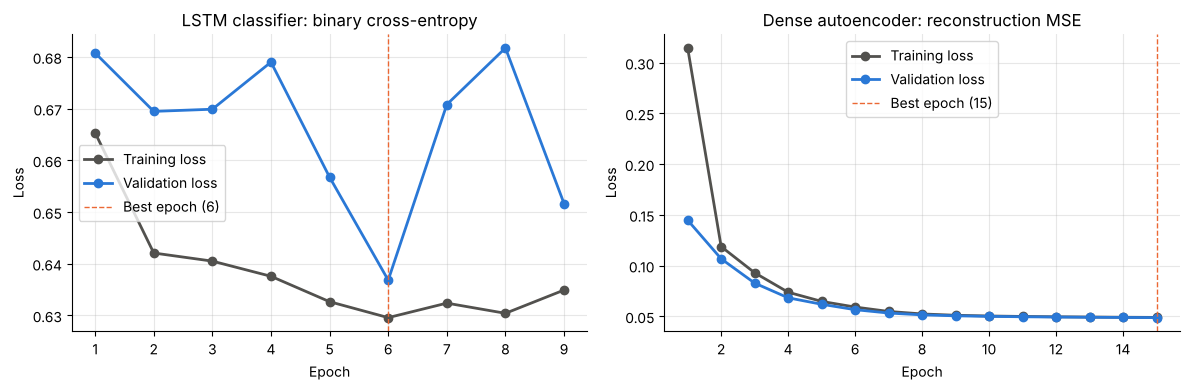

In [13]:
lstm_history_table = pd.DataFrame(lstm_history.history)
lstm_history_table.index = np.arange(1, len(lstm_history_table) + 1)
lstm_history_table.index.name = "epoch"
autoencoder_history_table = pd.DataFrame(autoencoder_history.history)
autoencoder_history_table.index = np.arange(1, len(autoencoder_history_table) + 1)
autoencoder_history_table.index.name = "epoch"

lstm_history_table.round(5).to_csv(RESULTS_DIR / "05_lstm_history.csv")
autoencoder_history_table.round(5).to_csv(RESULTS_DIR / "05_autoencoder_history.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
history_panels = [
    (axes[0], lstm_history_table, lstm_best_epoch, "LSTM classifier: binary cross-entropy"),
    (axes[1], autoencoder_history_table, autoencoder_best_epoch, "Dense autoencoder: reconstruction MSE"),
]
for panel, history_table, best_epoch, title in history_panels:
    panel.plot(history_table.index, history_table["loss"], color=NEUTRAL_COLOR, marker="o", linewidth=2, label="Training loss")
    panel.plot(history_table.index, history_table["val_loss"], color=DEEP_COLOR, marker="o", linewidth=2, label="Validation loss")
    panel.axvline(best_epoch, color=THEFT_COLOR, linestyle="--", linewidth=1, label=f"Best epoch ({best_epoch})")
    panel.set_xlabel("Epoch")
    panel.set_ylabel("Loss")
    panel.set_title(title)
    panel.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_training_curves.png", dpi=120)
plt.show()

**Reading the curves.**
- **LSTM:**
  - The training loss falls steadily.
  - The validation loss jumps around, with a clear low at epoch 6.
  - Early stopping kept epoch 6 and stopped three epochs later, which prevented further fitting to noise.
- **Autoencoder:**
  - Both losses fall quickly in the first 5 epochs and then flatten out.
  - The curves stay very close, so the autoencoder is **not overfitting**: it rebuilds unseen normal
    validation customers as well as training customers.
  - More epochs would only bring very small further improvements.

## 5. Example reconstructions
Two validation customers: one with a **typical** (median) reconstruction error and one with the **highest**
error. To make the plots readable in kWh, we undo the Notebook 02 scaling with the **saved** parameters:
`kWh = expm1(scaled × train_std + train_mean)`. Grey shading marks weeks that were **imputed** in
Notebook 02.

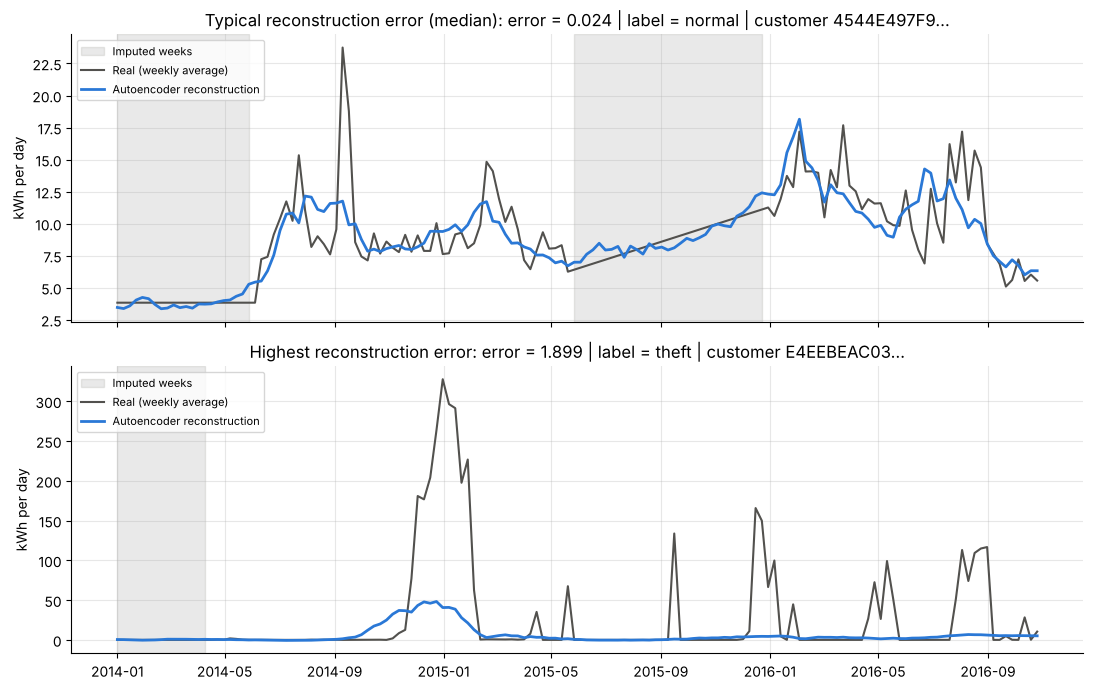

In [14]:
error_order = np.argsort(autoencoder_validation_error)
typical_row = error_order[len(error_order) // 2]
most_anomalous_row = error_order[-1]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
example_rows = [(axes[0], typical_row, "Typical reconstruction error (median)"),
                (axes[1], most_anomalous_row, "Highest reconstruction error")]
for panel, row, description in example_rows:
    real_kwh = np.expm1(X_validation[row] * LOG_TRAIN_STD + LOG_TRAIN_MEAN)
    rebuilt_kwh = np.expm1(validation_reconstruction[row] * LOG_TRAIN_STD + LOG_TRAIN_MEAN)
    imputed_weeks = observed_validation[row] == 0
    panel.fill_between(WEEK_START_DATES, 0, 1, where=imputed_weeks, color=NEUTRAL_COLOR, alpha=0.12,
                       transform=panel.get_xaxis_transform(), label="Imputed weeks")
    panel.plot(WEEK_START_DATES, real_kwh, color=NEUTRAL_COLOR, linewidth=1.5, label="Real (weekly average)")
    panel.plot(WEEK_START_DATES, rebuilt_kwh, color=DEEP_COLOR, linewidth=2, label="Autoencoder reconstruction")
    panel.set_ylabel("kWh per day")
    panel.set_title(f"{description}: error = {autoencoder_validation_error[row]:.3f} | "
                    f"label = {'theft' if y_validation[row] == 1 else 'normal'} | customer {validation_ids[row][:10]}…")
    panel.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_reconstruction_examples.png", dpi=120)
plt.show()

**What we see.**
- **Typical customer** (median error 0.024, labelled normal): the reconstruction follows the real weekly
  pattern closely, including the seasonal rise and fall. It also follows the flat and straight-line
  stretches that were imputed in Notebook 02 (grey).
- **Highest-error customer** (error 1.899, labelled theft): the real series has huge, irregular bursts
  (weekly averages of several hundred kWh per day) separated by near-zero periods. A model that learned
  normal usage cannot rebuild this pattern, so the error is large.

This is exactly how the anomaly score is meant to work. Remember, though, that **unusual is not the same
as theft**: some normal customers are unusual too, which is why the autoencoder's ranking is far from
perfect.

## 6. Validation comparison with the Notebook 04 baselines
The supervised models are compared with each other (LR, Random Forest, LSTM), and the unsupervised models
with each other (Isolation Forest, autoencoder). All numbers are on the **same 6,354 validation customers**.

In [15]:
notebook_04_metrics = pd.read_csv(RESULTS_DIR / "04_validation_metrics.csv", index_col="Model")

deep_metrics = pd.DataFrame({
    "Branch": ["Supervised", "Unsupervised"],
    "Validation ROC-AUC": [lstm_validation_auc, autoencoder_validation_auc],
    "Validation PR-AUC": [lstm_validation_pr_auc, autoencoder_validation_pr_auc],
    "Training time (s)": [lstm_training_seconds, autoencoder_training_seconds],
    "Epochs completed": [lstm_epochs_completed, autoencoder_epochs_completed],
    "Best epoch": [lstm_best_epoch, autoencoder_best_epoch],
}, index=["LSTM classifier", "Dense autoencoder"])
deep_metrics.index.name = "Model"

model_order = ["Logistic Regression", "Random Forest", "LSTM classifier", "Isolation Forest", "Dense autoencoder",
               "Average consumption alone", "Random ranking"]
validation_metrics = pd.concat([notebook_04_metrics, deep_metrics]).loc[model_order].round(4)
validation_metrics.to_csv(RESULTS_DIR / "05_validation_metrics.csv")
validation_metrics

,Branch,Validation ROC-AUC,Validation PR-AUC,Training time (s),Epochs completed,Best epoch
Model,,,,,,
Logistic Regression,Supervised,0.7216,0.2377,0.0616,NaN,NaN
Random Forest,Supervised,0.7628,0.3268,1.7017,NaN,NaN
LSTM classifier,Supervised,0.6925,0.2043,59.4168,9.0,6.0
Isolation Forest,Unsupervised,0.5863,0.1470,0.2423,NaN,NaN
Dense autoencoder,Unsupervised,0.6321,0.1539,6.1824,15.0,15.0
Average consumption alone,Reference (no training),0.6671,0.1897,NaN,NaN,NaN
Random ranking,Reference,0.5000,0.0850,NaN,NaN,NaN


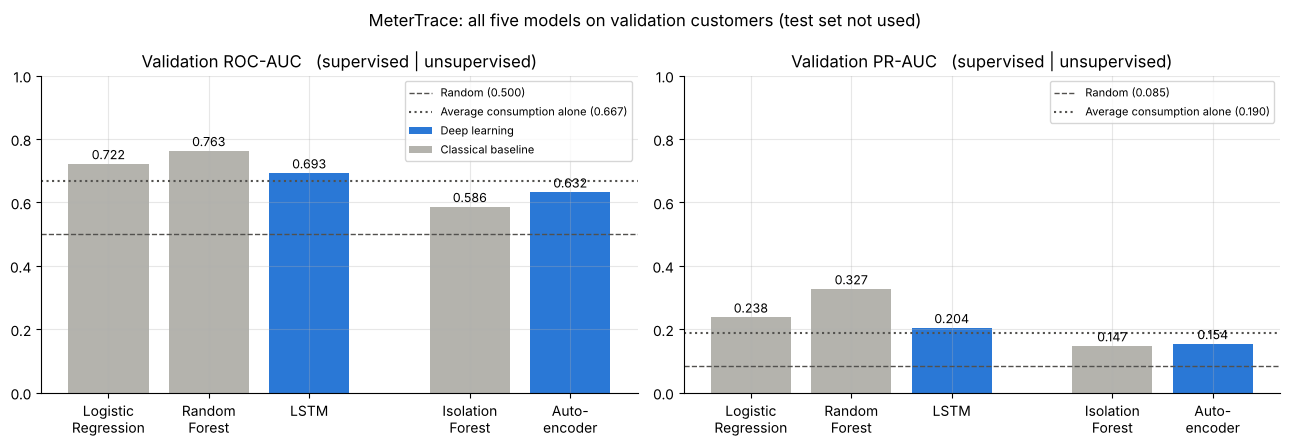

In [16]:
compared_models = ["Logistic Regression", "Random Forest", "LSTM classifier", "Isolation Forest", "Dense autoencoder"]
bar_colors = [CLASSICAL_COLOR, CLASSICAL_COLOR, DEEP_COLOR, CLASSICAL_COLOR, DEEP_COLOR]
bar_positions = np.array([0, 1, 2, 3.6, 4.6])          # a gap separates the two branches
reference_auc = validation_metrics.loc["Average consumption alone", "Validation ROC-AUC"]
reference_pr_auc = validation_metrics.loc["Average consumption alone", "Validation PR-AUC"]
random_pr_auc = validation_metrics.loc["Random ranking", "Validation PR-AUC"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for panel, metric, random_value, reference_value in [
        (axes[0], "Validation ROC-AUC", 0.5, reference_auc),
        (axes[1], "Validation PR-AUC", random_pr_auc, reference_pr_auc)]:
    values = validation_metrics.loc[compared_models, metric].to_numpy()
    panel.bar(bar_positions, values, color=bar_colors, width=0.8)
    for position, value in zip(bar_positions, values):
        panel.text(position, value + 0.015, f"{value:.3f}", ha="center", fontsize=9)
    panel.axhline(random_value, color=NEUTRAL_COLOR, linestyle="--", linewidth=1, label=f"Random ({random_value:.3f})")
    panel.axhline(reference_value, color=NEUTRAL_COLOR, linestyle=":", linewidth=1.5,
                  label=f"Average consumption alone ({reference_value:.3f})")
    panel.set_xticks(bar_positions)
    panel.set_xticklabels(["Logistic\nRegression", "Random\nForest", "LSTM", "Isolation\nForest", "Auto-\nencoder"])
    panel.set_ylim(0, 1)
    panel.set_title(f"{metric}   (supervised | unsupervised)")
    panel.legend(loc="upper right", fontsize=8)
axes[0].bar([0], [0], color=DEEP_COLOR, label="Deep learning")
axes[0].bar([0], [0], color=CLASSICAL_COLOR, label="Classical baseline")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("MeterTrace: all five models on validation customers (test set not used)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_validation_comparison.png", dpi=120)
plt.show()

**Summary on validation customers (test set not used).**

| Branch | Best model | Deep learning model | Did deep learning win? |
|---|---|---|---|
| Supervised | Random Forest (0.7628 / 0.3268) | LSTM (0.6925 / 0.2043) | **No.** The LSTM is below both feature-based models |
| Unsupervised | Dense autoencoder (0.6321 / 0.1539) | Dense autoencoder | **Yes.** It beats Isolation Forest (0.5863 / 0.1470) |

*(ROC-AUC / PR-AUC)*

**Honest interpretation.**
- **Why the features win:** the hand-made features summarise the **daily** readings, while both networks
  see only **weekly averages**, which smooth away day-level detail. The features also measure
  missingness from the real data, whereas the networks only see imputed values.
- **Small, untuned models:** the networks are deliberately small and trained for at most 15 epochs, with
  no tuning, as agreed for this project.
- **Ideas not tried:** a longer training run, giving the networks the `observed` mask as a second input,
  or the extensions listed in the proposal (CNNs, LSTM autoencoders). We did not try them, to keep the
  project simple and avoid tuning on validation results.
- **Final comparison:** this will be made on the **test** set in Notebook 06, with thresholds chosen on
  validation data.

## 7. Save the models and validation scores
- Models are saved in Keras' native `.keras` format in `models/` (git-ignored; re-run this notebook to
  re-create them).
- Validation scores are saved in **exactly the existing validation order** (same as Notebook 04 and the
  feature files), so Notebook 06 can combine all five models row by row.
- No test predictions are made.

In [17]:
lstm_model.save(MODEL_DIR / "lstm_classifier.keras")
autoencoder.save(MODEL_DIR / "dense_autoencoder.keras")

deep_validation_scores = pd.DataFrame({
    "FLAG": y_validation,
    "lstm_probability": lstm_validation_probability,
    "autoencoder_reconstruction_error": autoencoder_validation_error,
}, index=pd.Index(validation_ids, name="CONS_NO"))
deep_validation_scores.to_csv(RESULTS_DIR / "05_validation_scores.csv")

for path in sorted(MODEL_DIR.glob("*.keras")):
    print(f"{path.relative_to(PROJECT_ROOT)}: {path.stat().st_size / 1e6:.2f} MB")
print("outputs/results/05_validation_scores.csv:", deep_validation_scores.shape)

models/dense_autoencoder.keras: 0.29 MB
models/lstm_classifier.keras: 0.08 MB
outputs/results/05_validation_scores.csv: (6354, 3)


In [18]:
# Reload both models and confirm they give the same validation scores
reloaded_lstm = keras.models.load_model(MODEL_DIR / "lstm_classifier.keras")
reloaded_autoencoder = keras.models.load_model(MODEL_DIR / "dense_autoencoder.keras")

# Calling a model directly (model(inputs)) runs it once on all validation customers
reloaded_probability = reloaded_lstm(X_validation_sequence, training=False).numpy().ravel()
reloaded_error = np.mean((X_validation - reloaded_autoencoder(X_validation, training=False).numpy()) ** 2, axis=1)

print("Reloaded LSTM gives the same scores:       ", np.allclose(reloaded_probability, lstm_validation_probability, atol=1e-5))
print("Reloaded autoencoder gives the same scores:", np.allclose(reloaded_error, autoencoder_validation_error, atol=1e-5))
print("Saved row order equals Notebook 04 order:  ",
      bool((pd.read_csv(RESULTS_DIR / "05_validation_scores.csv", index_col=0).index == notebook_04_scores.index).all()))

Reloaded LSTM gives the same scores:        True
Reloaded autoencoder gives the same scores: True
Saved row order equals Notebook 04 order:   True


## What We Learned
Key ideas to be able to explain in the viva:

1. **LSTMs read sequences step by step.** The LSTM keeps a memory while reading 148 weeks in order and
   compresses them into 32 numbers before the final sigmoid layer. With only 4,385 parameters, it is a
   very small network.
2. **Autoencoders learn "normal" without labels as targets.** The autoencoder is trained to rebuild its
   own input through a 16-number bottleneck. Because it only saw normal customers, its reconstruction
   error works as an anomaly score: high error means unusual, **not** proven theft.
3. **Early stopping uses the validation set to choose the training length.** The LSTM stopped after 9
   epochs and restored epoch 6. The autoencoder used all 15 epochs. The validation loss guards against
   memorising the training customers.
4. **Class weights with Keras.** `class_weight={0: 0.547, 1: 5.861}`, computed from training labels only,
   makes the rare theft class count more in the loss. Training and validation losses are then on
   slightly different scales.
5. **Reproducibility needs effort.** Setting seeds for NumPy and TensorFlow and enabling deterministic
   operations made two complete runs give identical scores.
6. **Deep learning is not automatically better.** On validation data, the LSTM (ROC-AUC 0.6925) did
   **not** beat Logistic Regression or Random Forest on hand-made daily features. The autoencoder
   (0.6321) **did** beat Isolation Forest (0.5863). Measuring this honestly, instead of assuming it, is
   exactly what our proposal promised.
7. **The input representation matters.** Weekly averages are fast to train on but hide day-level detail,
   and imputed weeks look flat. The features from Notebook 03 were computed from real daily readings.
8. **The test set stays locked.** All numbers here are on validation customers. Thresholds and the single
   test evaluation happen in Notebook 06.